# ДЗ-2. Полный аудит A/B-теста: нарушения протокола и решение о запуске фичи

**Дисциплина:** Эксперименты и причинно-следственный вывод
**Выполнил:** Бутурлин А. И., магистратура НИЯУ МИФИ, программа «Управление внедрением ИИ в бизнес»

Файл данных `exp_data_seed_960134.csv` генерируется в этом ноутбуке (раздел 0) и лежит рядом с ноутбуком в репозитории.

## Условие (кратко)

Команда провела A/B-тест, но есть подозрение, что аналитик нарушил протокол. Данные (`exp_data_seed_{MY_SEED}.csv`): `user_id`, `variant` (control/test), `converted` (0/1), `error_flag` (0/1, guardrail), `weekend` (признак выходного), `platform` (0/1/2), `entry_time` (время входа в эксперимент, число от 0 до 1 — доля длительности теста; по подсказке из задания переводится в формат времени через `pd.to_timedelta(..., unit='D')`).

Истинный эффект фичи = 0, но в данных заложены артефакты: подглядывание (peeking), confounder (`weekend` влияет и на попадание в группу, и на конверсию), ложный сигнал в одном из сегментов `platform`, завышенные ошибки в test.

Что требуется:
1. Загрузить данные, базовая информация.
2. Pre-launch checks: SRM (хи-квадрат, 50/50) и баланс ковариат (`weekend`, `entry_time`).
3. Анализ первичной метрики: z-тест для долей, lift, 95 % ДИ, p-value — **без вывода о значимости** до следующих проверок.
4. Проверки корректности: guardrail (`error_flag`), сегменты по `platform` с поправкой на множественные проверки, peeking (связь `entry_time` и группы + график).
5. Коррекция (IPW / CUPED / стратификация / регрессия) и как меняется оценка эффекта; либо аргументированно «эксперимент невалиден».
6. Финальное продуктовое решение: rollout / не rollout / повторить с изменениями — с цифрами.

Разделы ниже повторяют пункты задания, в конце — общий вывод.

## 0. Подготовка и генерация данных

Код генерации взят из задания. Что я поменял и почему:

* **Seed зафиксирован** (`MY_SEED = 960134`): получен один раз как `np.random.randint(5000000)` и захардкожен, чтобы перезапуск ноутбука давал тот же файл, а числа в тексте совпадали с данными. Число участников берётся случайно (но воспроизводимо) из диапазона 1000–10000.
* `error_flag` приведён к `int` (в исходнике `float` из-за `np.zeros`).
* В исходном коде `print` сообщает, что файл сохранён в папку `exp_data/`, а `to_csv` пишет его в текущую папку без этого префикса — поправил сообщение, чтобы оно не вводило в заблуждение.
* Параметры генерации **не менял**. Задание допускает менять параметры рандомизации для улучшения данных; я этим не пользовался: на исходных параметрах все заложенные проблемы обнаруживаются (см. разделы 2–4), уникальность обеспечивают seed и случайное число участников, а неизменённый генератор исключает подозрение в подгонке данных под ответ.

Что видно уже при чтении генератора (проверю по данным, а не по комментариям):
* первое назначение `variant` по `time_of_entry > 0.4` (имитация peeking) **перезаписывается** следующей строкой `np.random.choice`, а дальше назначение зависит только от `weekend` и случайности. Значит, связи между `entry_time` и группой в данных может и не оказаться — комментарий «в тесте более поздние пользователи» нужно проверять, а не принимать на веру;
* доля test после всех переопределений — не 50 %, но насколько — зависит от двух случайных `p_`, т.е. от seed; SRM может быть как сильным, так и слабым;
* правило с `weekend` устроено так, что «test & weekend» всегда остаются в test, а «control & не-weekend» — в control: доля выходных пользователей в группах должна различаться очень сильно;
* в сегменте `platform == 2` конверсия test **заменяется** на Bernoulli(0.2) независимо от `weekend` — это искусственный подъём, который поправка на `weekend` не уберёт;
* ошибки: 2 % в control против 6 % в test — втрое.

In [1]:
import hashlib
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportions_ztest, proportion_confint, proportion_effectsize
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.power import NormalIndPower

warnings.filterwarnings("ignore")
pd.set_option("display.precision", 4)
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
COLORS = {"control": "#4C72B0", "test": "#DD8452"}

ALPHA = 0.05            # порог значимости по условию
EXPECTED_SHARE = 0.5    # ожидаемая доля каждой группы

def fmt_p(p):
    # очень маленькие p-value печатаются как 0 — показываю это явно
    return "< 1e-300" if p < 1e-300 else f"{p:.3g}"

In [2]:
# ===== Генерация данных (код из задания, выполняется один раз; seed зафиксирован) =====
MY_SEED = 960134           # получен один раз как np.random.randint(5000000) и зафиксирован
np.random.seed(MY_SEED)

# Параметры
n_users = np.random.randint(1000, 10000, size=1)[0]
true_effect = 0            # на самом деле эффекта нет, но данные будут содержать артефакты
expected_ratio = 0.5

# ----- НАРУШЕНИЕ 1: Peeking (ранняя остановка) -----
time_of_entry = np.random.uniform(0, 1, n_users)                   # время от 0 до 1
variant = np.where(time_of_entry > 0.4, 'test', 'control')          # (это назначение ниже перезаписывается)

# имитация SRM: неравные группы
p_ = np.random.uniform(low=0.4001, high=0.599999, size=1)[0]
variant = np.random.choice(['control', 'test'], size=n_users, p=[p_, 1-p_])

# ----- НАРУШЕНИЕ 2: confounder (weekend влияет и на участие, и на результат) -----
weekend = np.random.binomial(1, 0.3, n_users)
p_ = np.random.uniform(low=0.40001, high=0.499999, size=1)[0]
variant = np.where((variant == 'test') & (weekend == 1), 'test',
          np.where((variant == 'control') & (weekend == 0), 'control',
          np.random.choice(['control', 'test'], size=n_users, p=[p_, 1-p_])))   # оставляем некоторую случайность

# конверсия зависит от weekend (истинный эффект фичи = 0)
conversion_prob = 0.1 + 0.05 * weekend
converted = np.random.binomial(1, conversion_prob, n_users)

# ----- НАРУШЕНИЕ 3: множественные проверки и сегментация -----
p_ = np.random.uniform(low=0.02, high=0.15, size=1)[0]
p_2 = np.random.uniform(low=0.25, high=0.35, size=1)[0]
platform = np.random.choice([0, 1, 2], size=n_users, p=[1-p_2-p_, p_2, p_])
# в сегменте platform=2 тестовая группа получила искусственный подъём конверсии (ложный сигнал)
converted = np.where((platform == 2) & (variant == 'test'),
                     np.random.binomial(1, 0.2, size=len(converted)),
                     converted)

# ----- Guardrail: частота ошибок (должна быть одинаковой, но в test завышена) -----
error_flag = np.zeros(n_users)
error_flag[variant == 'control'] = np.random.binomial(1, 0.02, sum(variant == 'control'))
error_flag[variant == 'test'] = np.random.binomial(1, 0.06, sum(variant == 'test'))

df_gen = pd.DataFrame({
    'user_id': range(n_users),
    'variant': variant,
    'converted': converted,
    'error_flag': error_flag.astype(int),     # в исходнике float — привёл к int
    'weekend': weekend,
    'platform': platform,
    'entry_time': time_of_entry,
})

DATA_PATH = f'exp_data_seed_{MY_SEED}.csv'    # файл сохраняется в текущую папку (в исходнике print обещал папку exp_data/)
df_gen.to_csv(DATA_PATH, index=False)

with open(DATA_PATH, "rb") as f:
    md5 = hashlib.md5(f.read()).hexdigest()
print(f"Данные сохранены в файл {DATA_PATH}: {n_users} пользователей, seed = {MY_SEED}, md5 = {md5}")
print(f"Размеры групп: control={sum(variant == 'control')}, test={sum(variant == 'test')}")

Данные сохранены в файл exp_data_seed_960134.csv: 9853 пользователей, seed = 960134, md5 = 57d4f7c425aceb4349a8bae8e6ca2469
Размеры групп: control=5896, test=3957


## 1. Загрузка данных и базовая информация

Дальше работаю **только с файлом**, как если бы его прислали готовым, — переменные генератора не использую.

In [3]:
df = pd.read_csv(DATA_PATH)

# entry_time хранится как число от 0 до 1 — по подсказке из задания переводим в формат времени
df["time_delta"] = pd.to_timedelta(df["entry_time"], unit="D")
df["is_test"] = (df["variant"] == "test").astype(int)

print("Размер таблицы:", df.shape)
print("\nТипы и пропуски:")
print(pd.DataFrame({"dtype": df.dtypes, "n_missing": df.isna().sum()}))
print("\nДубликатов user_id:", df["user_id"].duplicated().sum())
print("Значения variant:", df["variant"].unique().tolist(), "| platform:", sorted(df["platform"].unique().tolist()))
print("converted:", sorted(df["converted"].unique().tolist()), "| error_flag:", sorted(df["error_flag"].unique().tolist()),
      "| weekend:", sorted(df["weekend"].unique().tolist()))
print(f"entry_time: от {df['entry_time'].min():.4f} до {df['entry_time'].max():.4f} "
      f"(в формате времени: от {df['time_delta'].min()} до {df['time_delta'].max()})")
df.head()

Размер таблицы: (9853, 9)

Типы и пропуски:
                      dtype  n_missing
user_id               int64          0
variant                 str          0
converted             int64          0
error_flag            int64          0
weekend               int64          0
platform              int64          0
entry_time          float64          0
time_delta  timedelta64[ns]          0
is_test               int64          0

Дубликатов user_id: 0
Значения variant: ['control', 'test'] | platform: [0, 1, 2]
converted: [0, 1] | error_flag: [0, 1] | weekend: [0, 1]
entry_time: от 0.0000 до 0.9995 (в формате времени: от 0 days 00:00:03.464819841 до 0 days 23:59:15.015124530)


,user_id,variant,converted,error_flag,weekend,platform,entry_time,time_delta,is_test
0,0,control,0,0,0,1,0.6316,0 days 15:09:29.373165561,0
1,1,test,1,0,1,1,0.6768,0 days 16:14:33.825295510,1
2,2,control,0,0,0,0,0.6895,0 days 16:32:55.364218028,0
3,3,control,0,0,0,1,0.0624,0 days 01:29:48.919299852,0
4,4,control,0,0,0,0,0.6599,0 days 15:50:14.970289758,0


In [4]:
summary = (
    df.groupby("variant")
      .agg(n_users=("user_id", "size"),
           conversion=("converted", "mean"),
           error_rate=("error_flag", "mean"),
           weekend_share=("weekend", "mean"),
           entry_time_mean=("entry_time", "mean"))
)
summary.insert(1, "share", summary["n_users"] / summary["n_users"].sum())
summary

,n_users,share,conversion,error_rate,weekend_share,entry_time_mean
variant,,,,,,
control,5896,0.5984,0.1038,0.0176,0.1211,0.5053
test,3957,0.4016,0.1329,0.0614,0.5636,0.5022


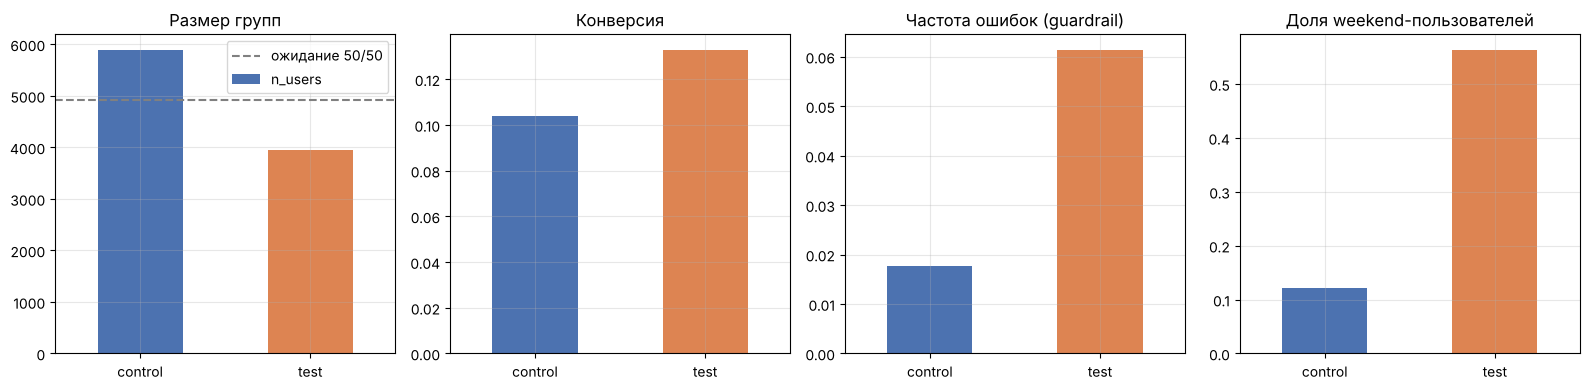

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col, title in zip(axes,
                          ["n_users", "conversion", "error_rate", "weekend_share"],
                          ["Размер групп", "Конверсия", "Частота ошибок (guardrail)", "Доля weekend-пользователей"]):
    summary[col].plot.bar(ax=ax, color=[COLORS["control"], COLORS["test"]], rot=0)
    ax.set_title(title); ax.set_xlabel("")
axes[0].axhline(len(df) / 2, ls="--", c="gray", label="ожидание 50/50"); axes[0].legend()
plt.tight_layout(); plt.show()

**Что видно на первом шаге.** Группы заметно не равны (control больше). Конверсия в test выше примерно на 3 п.п. (п.п. — процентные пункты), ошибок в test в несколько раз больше, а доля пользователей выходного дня в test — в разы выше, чем в control. Последнее особенно подозрительно: признак, который сам влияет на конверсию, распределён по группам неравномерно. Всё дальше — статистические проверки этих наблюдений.

## 2. Pre-launch checks: SRM и баланс ковариат

Проверки «до анализа»: если здесь что-то не так, на результаты по конверсии полагаться нельзя, как бы красиво они ни выглядели.

* **SRM** — хи-квадрат тест согласия против 50/50 (как в задании) плюс точный биномиальный тест и доверительный интервал для доли test.
* **Баланс ковариат** — `weekend` (бинарная: сравниваю доли z-тестом/хи-квадрат, для контроля Welch t-тест на 0/1) и `entry_time` (непрерывная, равномерная — U-тест Манна–Уитни как основной, тест Колмогорова–Смирнова на различие распределений целиком, Welch t-тест для контроля). Для обеих считаю стандартизованную разницу средних (SMD): она показывает размер дисбаланса и не зависит от n (ориентир |SMD| < 0.1).

In [6]:
warnings_list = []   # сюда складываю найденные нарушения для финального решения

n_total = len(df)
n_c = int((df["is_test"] == 0).sum()); n_t = int(df["is_test"].sum())
share_test = n_t / n_total

chi2_stat, p_srm = stats.chisquare(f_obs=[n_c, n_t], f_exp=[n_total * EXPECTED_SHARE] * 2)
p_binom = stats.binomtest(n_t, n_total, EXPECTED_SHARE).pvalue
ci_srm = proportion_confint(n_t, n_total, method="wilson")

print(f"control = {n_c}, test = {n_t}, доля test = {share_test:.4f} (95% ДИ {ci_srm[0]:.4f}–{ci_srm[1]:.4f})")
print(f"Хи-квадрат = {chi2_stat:.2f}, p-value = {p_srm:.3g}; биномиальный тест: p = {p_binom:.3g}")
if p_srm < ALPHA:
    print("Вердикт: ⚠ SRM обнаружен")
    warnings_list.append(f"SRM: доля test {share_test:.3f} вместо 0.5 (p = {p_srm:.1e})")
else:
    print("Вердикт: SRM нет")

control = 5896, test = 3957, доля test = 0.4016 (95% ДИ 0.3920–0.4113)
Хи-квадрат = 381.58, p-value = 5.63e-85; биномиальный тест: p = 1.97e-85
Вердикт: ⚠ SRM обнаружен


In [7]:
def smd(a, b):
    # стандартизованная разница средних (test − control) с pooled sd
    return (np.mean(b) - np.mean(a)) / np.sqrt((np.var(a, ddof=1) + np.var(b, ddof=1)) / 2)

c_mask, t_mask = df["is_test"] == 0, df["is_test"] == 1

# --- weekend (бинарная ковариата)
wk_c, wk_t = df.loc[c_mask, "weekend"], df.loc[t_mask, "weekend"]
z_wk, p_wk = proportions_ztest([wk_c.sum(), wk_t.sum()], [n_c, n_t])
p_wk_t = stats.ttest_ind(wk_c, wk_t, equal_var=False).pvalue
print(f"weekend: доля в control = {wk_c.mean():.3f}, в test = {wk_t.mean():.3f}, SMD = {smd(wk_c, wk_t):+.2f}")
print(f"  z-тест долей: p = {fmt_p(p_wk)}; Welch t-тест на 0/1: p = {fmt_p(p_wk_t)}")

# и «с другой стороны»: как weekend влияет на вероятность попасть в test
print("  P(test | weekend):")
print(pd.crosstab(df["weekend"], df["variant"], normalize="index").round(3))

# --- entry_time (непрерывная ковариата)
et_c, et_t = df.loc[c_mask, "entry_time"], df.loc[t_mask, "entry_time"]
p_et_u = stats.mannwhitneyu(et_c, et_t, alternative="two-sided").pvalue
p_et_ks = stats.ks_2samp(et_c, et_t).pvalue
p_et_t = stats.ttest_ind(et_c, et_t, equal_var=False).pvalue
print(f"\nentry_time: среднее control = {et_c.mean():.4f}, test = {et_t.mean():.4f}; медианы {et_c.median():.4f} vs {et_t.median():.4f}; SMD = {smd(et_c, et_t):+.3f}")
print(f"  U-тест: p = {p_et_u:.3f}; Колмогоров–Смирнов: p = {p_et_ks:.3f}; Welch t: p = {p_et_t:.3f}")

print()
if p_wk < ALPHA:
    print("⚠ Дисбаланс по weekend — confounder (weekend влияет и на группу, и на конверсию)")
    warnings_list.append(f"Confounder: доля weekend в test {wk_t.mean():.2f} против {wk_c.mean():.2f} в control (p {fmt_p(p_wk)})")
else:
    print("Баланс по weekend в норме")
if p_et_u < ALPHA:
    print("⚠ Дисбаланс по entry_time между группами")
    warnings_list.append("Дисбаланс по entry_time")
else:
    print("Баланс по entry_time в норме (значимых различий нет)")

weekend: доля в control = 0.121, в test = 0.564, SMD = +1.05
  z-тест долей: p = < 1e-300; Welch t-тест на 0/1: p = < 1e-300
  P(test | weekend):
variant  control   test
weekend                
0          0.750  0.250
1          0.243  0.757

entry_time: среднее control = 0.5053, test = 0.5022; медианы 0.5071 vs 0.5054; SMD = -0.011
  U-тест: p = 0.603; Колмогоров–Смирнов: p = 0.760; Welch t: p = 0.596

⚠ Дисбаланс по weekend — confounder (weekend влияет и на группу, и на конверсию)
Баланс по entry_time в норме (значимых различий нет)


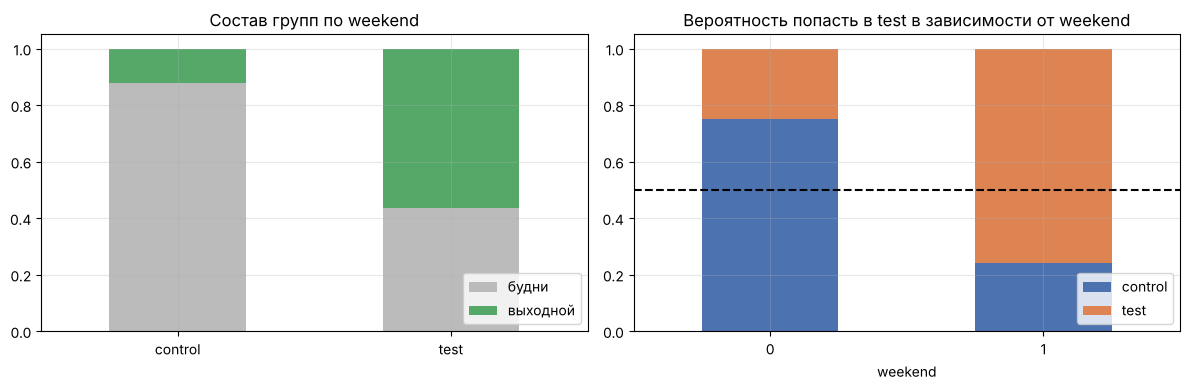

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
pd.crosstab(df["variant"], df["weekend"], normalize="index").plot.bar(ax=axes[0], stacked=True, rot=0,
                                                                        color=["#BBBBBB", "#55A868"])
axes[0].set_title("Состав групп по weekend"); axes[0].set_xlabel(""); axes[0].legend(["будни", "выходной"], loc="lower right")

pd.crosstab(df["weekend"], df["variant"], normalize="index").plot.bar(ax=axes[1], stacked=True, rot=0,
                                                                        color=[COLORS["control"], COLORS["test"]])
axes[1].axhline(0.5, ls="--", c="k"); axes[1].set_title("Вероятность попасть в test в зависимости от weekend")
axes[1].set_xlabel("weekend"); axes[1].legend(loc="lower right")
plt.tight_layout(); plt.show()

**Вывод по п. 2.**
* **SRM обнаружен**: доля test ≈ 0.40 вместо 0.50, p-value практически нулевое. Это ошибка механизма распределения (или потеря части логов одной группы), и пересчётом её не исправить.
* **Confounder по `weekend`**: в test больше половины пользователей — выходного дня, в control — около 12 %. Иначе говоря, пользователь выходного дня попадал в test с вероятностью ≈ 0.76, будничный — ≈ 0.25. Так как в выходные конверсия выше, «сырое» сравнение групп будет смешивать эффект фичи с эффектом выходного дня — именно в пользу test.
* **`entry_time` сбалансирован**: распределения времени входа в группах не различаются ни по среднему, ни по форме. Запомню это для проверки на peeking в п. 4.

Ловушка: `weekend` легко принять за «ещё одну метрику» и не проверять. Но это ковариата, которая связана и с назначением, и с исходом, — классический confounder.

## 3. Первичная метрика: конверсия (без вывода о значимости)

Считаю то, что посчитал бы «обычный» аналитик: z-тест для двух долей, абсолютный lift (в п.п.), относительный lift (в %), 95 % доверительный интервал разницы и p-value. **Вывод о значимости не делаю** — пока не пройдены проверки п. 4. Z-тест и t-тест на бинарных данных при таких n дают практически одно и то же; показываю оба для контроля.

In [9]:
conv_c, conv_t = df.loc[c_mask, "converted"], df.loc[t_mask, "converted"]
k_c, k_t = int(conv_c.sum()), int(conv_t.sum())
p_c, p_t = k_c / n_c, k_t / n_t

z_conv, p_conv = proportions_ztest([k_c, k_t], [n_c, n_t])
p_conv_t = stats.ttest_ind(conv_c, conv_t, equal_var=False).pvalue
lift_abs = p_t - p_c
lift_rel = lift_abs / p_c
se_diff = np.sqrt(p_c * (1 - p_c) / n_c + p_t * (1 - p_t) / n_t)
ci_lift = lift_abs + np.array([-1, 1]) * stats.norm.ppf(0.975) * se_diff

print(f"Конверсия: control = {p_c:.4f} ({k_c}/{n_c}), test = {p_t:.4f} ({k_t}/{n_t})")
print(f"Lift абсолютный = {lift_abs * 100:+.2f} п.п., 95% ДИ [{ci_lift[0] * 100:+.2f}; {ci_lift[1] * 100:+.2f}] п.п.")
print(f"Lift относительный = {lift_rel * 100:+.1f} %")
print(f"z-тест долей: z = {z_conv:.2f}, p = {p_conv:.3g}; Welch t-тест (контроль): p = {p_conv_t:.3g}")
print("\n(Вывод о значимости пока НЕ делаю — сначала проверки п. 4.)")

Конверсия: control = 0.1038 (612/5896), test = 0.1329 (526/3957)
Lift абсолютный = +2.91 п.п., 95% ДИ [+1.60; +4.23] п.п.
Lift относительный = +28.1 %
z-тест долей: z = -4.43, p = 9.21e-06; Welch t-тест (контроль): p = 1.4e-05

(Вывод о значимости пока НЕ делаю — сначала проверки п. 4.)


На бумаге картина для фичи отличная: примерно +3 п.п. (+28 % относительно), доверительный интервал не задевает ноль, p-value на уровне 10⁻⁵. Если бы аналитик остановился здесь, он бы рекомендовал запуск. Дальше — почему этого делать нельзя.

## 4. Проверки корректности: guardrail, сегменты, peeking

### 4.1 Guardrail — частота ошибок

Сравниваю доли ошибок: z-тест двух долей, точный тест Фишера (на всякий случай — доли небольшие), относительный риск с 95 % ДИ, интервалы Уилсона для каждой группы.

control: 104 ошибок из 5896 → 0.0176 (95% ДИ 0.0146–0.0213)
test:    243 ошибок из 3957 → 0.0614 (95% ДИ 0.0543–0.0693)
Разница = +4.38 п.п.; относительный риск = 3.48 (95% ДИ 2.78–4.36)
z-тест: p = 6.97e-31; точный тест Фишера: p = 2.66e-30

⚠ Guardrail нарушен: ошибок в test значимо больше → тест должен быть остановлен независимо от конверсии


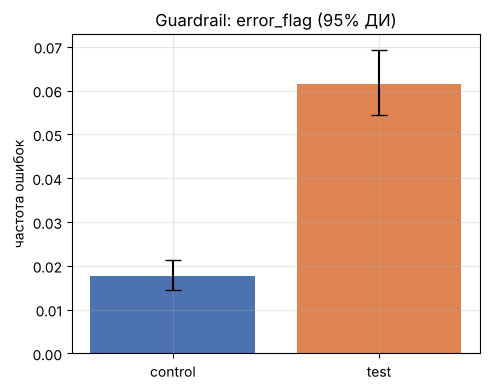

In [10]:
err_c, err_t = df.loc[c_mask, "error_flag"], df.loc[t_mask, "error_flag"]
e_c, e_t = int(err_c.sum()), int(err_t.sum())
r_c, r_t = e_c / n_c, e_t / n_t

z_err, p_err = proportions_ztest([e_c, e_t], [n_c, n_t])
p_fisher = stats.fisher_exact([[e_c, n_c - e_c], [e_t, n_t - e_t]]).pvalue
ci_ec = proportion_confint(e_c, n_c, method="wilson"); ci_et = proportion_confint(e_t, n_t, method="wilson")
rr = r_t / r_c
rr_ci = np.exp(np.log(rr) + np.array([-1, 1]) * 1.96 * np.sqrt(1 / e_t - 1 / n_t + 1 / e_c - 1 / n_c))

print(f"control: {e_c} ошибок из {n_c} → {r_c:.4f} (95% ДИ {ci_ec[0]:.4f}–{ci_ec[1]:.4f})")
print(f"test:    {e_t} ошибок из {n_t} → {r_t:.4f} (95% ДИ {ci_et[0]:.4f}–{ci_et[1]:.4f})")
print(f"Разница = {(r_t - r_c) * 100:+.2f} п.п.; относительный риск = {rr:.2f} (95% ДИ {rr_ci[0]:.2f}–{rr_ci[1]:.2f})")
print(f"z-тест: p = {p_err:.3g}; точный тест Фишера: p = {p_fisher:.3g}")

if p_err < ALPHA and r_t > r_c:
    print("\n⚠ Guardrail нарушен: ошибок в test значимо больше → тест должен быть остановлен независимо от конверсии")
    warnings_list.append(f"Guardrail: ошибки {r_t:.3f} в test против {r_c:.3f} в control, риск ×{rr:.1f} (p = {p_err:.1e})")
else:
    print("\nGuardrail в норме")

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(["control", "test"], [r_c, r_t], color=[COLORS["control"], COLORS["test"]],
       yerr=[[r_c - ci_ec[0], r_t - ci_et[0]], [ci_ec[1] - r_c, ci_et[1] - r_t]], capsize=6)
ax.set_ylabel("частота ошибок"); ax.set_title("Guardrail: error_flag (95% ДИ)")
plt.tight_layout(); plt.show()

**Вывод по guardrail.** Ошибок в test в 3,5 раза больше, чем в control (6,1 % против 1,8 %), и разница статистически несомненна. По правилу из задания этого уже достаточно, чтобы остановить тест: фича ломает страницу, какой бы ни была конверсия. Отдельная ловушка: ошибка загрузки обычно *снижает* конверсию, то есть при честном сравнении test выглядел бы ещё хуже, чем в п. 3, — ещё один признак, что «+3 п.п.» получены не за счёт фичи.

### 4.2 Анализ сегментов по `platform` с поправкой на множественные проверки

Считаю эффект (test − control) в каждом из трёх уровней `platform`: z-тест, ДИ, p-value. Затем применяю две поправки: Бонферрони (консервативная, контролирует вероятность хотя бы одной ложной находки) и Бенджамини–Хохберга (FDR, контролирует долю ложных находок среди отвергнутых). Три сегмента — три проверки, поэтому порог Бонферрони 0.05/3 ≈ 0.0167.

Ловушка, которую проверю отдельно: confounder по `weekend` никуда не делся *внутри* сегментов, поэтому «сырой» сегментный эффект может быть значимым просто из-за `weekend`. Для каждого сегмента посчитаю и скорректированный на `weekend` эффект (регрессия).

In [11]:
seg_rows = []
for pl, g in df.groupby("platform"):
    gc, gt = g[g["is_test"] == 0], g[g["is_test"] == 1]
    kc, kt = int(gc["converted"].sum()), int(gt["converted"].sum())
    pc, pt = kc / len(gc), kt / len(gt)
    _, p = proportions_ztest([kc, kt], [len(gc), len(gt)])
    se = np.sqrt(pc * (1 - pc) / len(gc) + pt * (1 - pt) / len(gt))
    # тот же эффект, но с поправкой на weekend (линейная модель, робастные ошибки)
    m = smf.ols("converted ~ is_test + weekend", data=g).fit(cov_type="HC1")
    seg_rows.append({"platform": pl, "n": len(g), "n_test": len(gt), "share_weekend_test": gt["weekend"].mean(),
                     "share_weekend_control": gc["weekend"].mean(),
                     "conv_control": pc, "conv_test": pt, "lift_pp": (pt - pc) * 100,
                     "ci_low": (pt - pc - 1.96 * se) * 100, "ci_high": (pt - pc + 1.96 * se) * 100, "p_raw": p,
                     "lift_adj_pp": m.params["is_test"] * 100, "p_adj_raw": m.pvalues["is_test"]})
seg = pd.DataFrame(seg_rows).set_index("platform")

# поправки на множественные проверки — отдельно для сырых и для скорректированных на weekend p-value
for col, new in [("p_raw", ""), ("p_adj_raw", "_wk")]:
    rej_b, p_b, _, _ = multipletests(seg[col], alpha=ALPHA, method="bonferroni")
    rej_f, p_f, _, _ = multipletests(seg[col], alpha=ALPHA, method="fdr_bh")
    seg[f"p_bonf{new}"] = p_b; seg[f"sig_bonf{new}"] = rej_b
    seg[f"p_fdr{new}"] = p_f; seg[f"sig_fdr{new}"] = rej_f

print("Сырой эффект по сегментам (без учёта weekend):")
print(seg[["n", "n_test", "conv_control", "conv_test", "lift_pp", "ci_low", "ci_high", "p_raw", "p_bonf", "sig_bonf", "p_fdr", "sig_fdr"]].round(4))
print("\nЭффект по сегментам после поправки на weekend (регрессия) и затем на множественные проверки:")
print(seg[["share_weekend_control", "share_weekend_test", "lift_adj_pp", "p_adj_raw", "p_bonf_wk", "sig_bonf_wk", "p_fdr_wk", "sig_fdr_wk"]].round(4))

Сырой эффект по сегментам (без учёта weekend):
             n  n_test  conv_control  conv_test  lift_pp  ci_low  ci_high  \
platform                                                                    
0         5497    2185        0.1063     0.1277   2.1409  0.3916   3.8902   
1         3336    1350        0.1027     0.1252   2.2466  0.0332   4.4600   
2         1020     422        0.0936     0.1848   9.1189  4.7407  13.4971   

           p_raw  p_bonf  sig_bonf   p_fdr  sig_fdr  
platform                                             
0         0.0148  0.0445      True  0.0222     True  
1         0.0433  0.1298     False  0.0433     True  
2         0.0000  0.0001      True  0.0001     True  

Эффект по сегментам после поправки на weekend (регрессия) и затем на множественные проверки:
          share_weekend_control  share_weekend_test  lift_adj_pp  p_adj_raw  \
platform                                                                      
0                        0.1244              

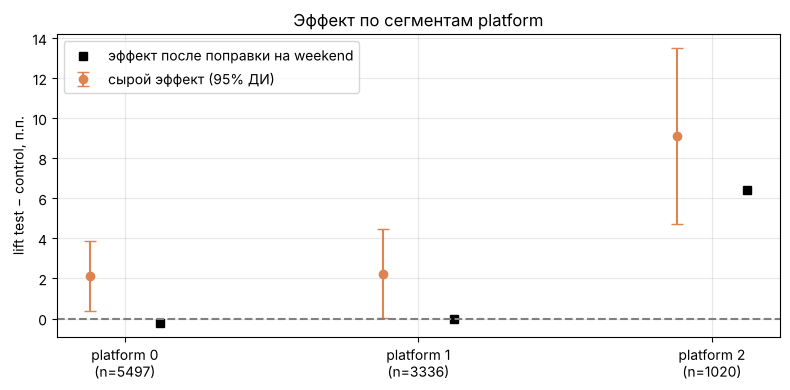

Сегменты, значимые после Бонферрони (сырой эффект): [0, 2]
Сегменты, значимые после Бонферрони И поправки на weekend: [2]


In [12]:
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(seg))
ax.errorbar(x - 0.12, seg["lift_pp"], yerr=[seg["lift_pp"] - seg["ci_low"], seg["ci_high"] - seg["lift_pp"]],
            fmt="o", capsize=4, color=COLORS["test"], label="сырой эффект (95% ДИ)")
ax.plot(x + 0.12, seg["lift_adj_pp"], "s", color="k", label="эффект после поправки на weekend")
ax.axhline(0, ls="--", c="gray")
ax.set_xticks(x); ax.set_xticklabels([f"platform {i}\n(n={n})" for i, n in zip(seg.index, seg["n"])])
ax.set_ylabel("lift test − control, п.п."); ax.set_title("Эффект по сегментам platform"); ax.legend()
plt.tight_layout(); plt.show()

sig_after = seg.index[seg["sig_bonf"]].tolist()
sig_after_wk = seg.index[seg["sig_bonf_wk"]].tolist()
print("Сегменты, значимые после Бонферрони (сырой эффект):", sig_after)
print("Сегменты, значимые после Бонферрони И поправки на weekend:", sig_after_wk)
if sig_after_wk:
    warnings_list.append(f"Изолированный сигнал в сегменте platform={sig_after_wk} (post-hoc, малый сегмент)")

**Вывод по сегментам.** В «сыром» виде эффект положительный во всех трёх сегментах, и после Бонферрони значимыми остаются два (platform 0 и 2). Но это иллюзия: в каждом сегменте в test больше пользователей выходного дня, и после поправки на `weekend` эффект в platform 0 и 1 обнуляется. Значимым остаётся только **platform 2**: +6 п.п. даже после поправки на `weekend` и на множественные проверки.

Почему сегментный анализ не может быть единственным основанием для запуска:
1. **Множественные сравнения.** Чем больше сегментов, тем выше шанс найти «значимый» случайно; поправки снижают этот риск, но не убирают его — особенно если сегментов десятки, а не три.
2. **Post-hoc.** Сегмент выбран после просмотра данных, а не заявлен до теста. Находка в platform 2 — это гипотеза, которую нужно проверить отдельным, заранее спланированным тестом, а не результат.
3. **Малая выборка в сегменте.** В platform 2 около 10 % пользователей; оценка эффекта там шумная, доверительный интервал широкий, и смещение из-за любых артефактов (баги логирования, особая аудитория) проявляется сильнее.
4. **Confounder работает и внутри сегментов**: без поправки на `weekend` два из трёх сегментов выглядели бы «победившими».
5. **Несогласованность с общим результатом**: если фича работает только на одной платформе, нужно понять механизм (почему именно там?), а не запускать всем. Кроме того, именно в данных задания известно, что подъём в platform 2 — искусственный; в реальной жизни этого знания нет, и единственная защита — повторная проверка.

### 4.3 Peeking (неявный): связь `entry_time` и варианта

Подглядывание и остановка по времени оставляют след в данных: если тест остановили в момент, когда p-value «пробило» порог, группы могут оказаться несбалансированы по времени входа (например, в test больше поздних пользователей). Проверяю:
1. распределение `entry_time` по группам (гистограмма, ECDF, тесты из п. 2);
2. долю test по времени — ровная ли линия;
3. динамику конверсии во времени по группам — нет ли тренда;
4. «что видел бы аналитик, подглядывая каждые 1000 пользователей» — путь p-value по мере накопления данных (по условию тест останавливали именно так).

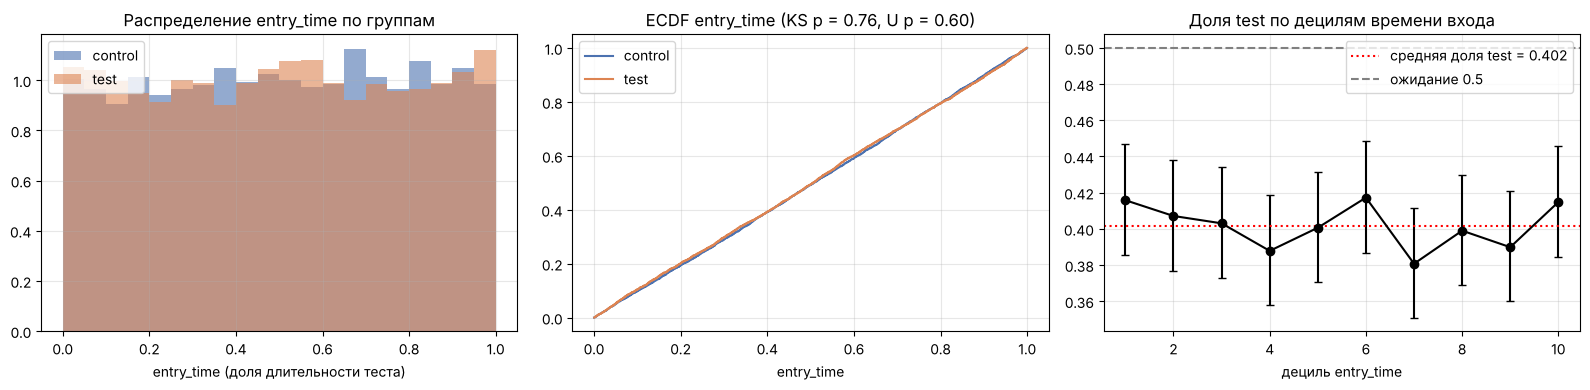

Хи-квадрат независимости (дециль времени × группа): p = 0.755
Корреляция Спирмена entry_time ~ is_test: -0.0052


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

bins_t = np.linspace(0, 1, 21)
axes[0].hist(et_c, bins=bins_t, alpha=0.6, density=True, color=COLORS["control"], label="control")
axes[0].hist(et_t, bins=bins_t, alpha=0.6, density=True, color=COLORS["test"], label="test")
axes[0].set_title("Распределение entry_time по группам"); axes[0].set_xlabel("entry_time (доля длительности теста)"); axes[0].legend()

for s, name in [(et_c, "control"), (et_t, "test")]:
    xs = np.sort(s.values); ys = np.arange(1, len(xs) + 1) / len(xs)
    axes[1].step(xs, ys, where="post", color=COLORS[name], label=name)
axes[1].set_title(f"ECDF entry_time (KS p = {p_et_ks:.2f}, U p = {p_et_u:.2f})"); axes[1].set_xlabel("entry_time"); axes[1].legend()

df["time_decile"] = pd.qcut(df["entry_time"], 10, labels=False) + 1
by_time = df.groupby("time_decile").agg(share_test=("is_test", "mean"), n=("user_id", "size"))
ci_t = np.array([proportion_confint(int(s * n), int(n), method="wilson") for s, n in zip(by_time["share_test"], by_time["n"])])
axes[2].errorbar(by_time.index, by_time["share_test"], yerr=[by_time["share_test"] - ci_t[:, 0], ci_t[:, 1] - by_time["share_test"]],
                 fmt="o-", capsize=3, color="k")
axes[2].axhline(share_test, ls=":", c="red", label=f"средняя доля test = {share_test:.3f}")
axes[2].axhline(0.5, ls="--", c="gray", label="ожидание 0.5")
axes[2].set_title("Доля test по децилям времени входа"); axes[2].set_xlabel("дециль entry_time"); axes[2].legend()
plt.tight_layout(); plt.show()

p_time_dec = stats.chi2_contingency(pd.crosstab(df["time_decile"], df["variant"])).pvalue
print(f"Хи-квадрат независимости (дециль времени × группа): p = {p_time_dec:.3f}")
print(f"Корреляция Спирмена entry_time ~ is_test: {stats.spearmanr(df['entry_time'], df['is_test']).statistic:+.4f}")

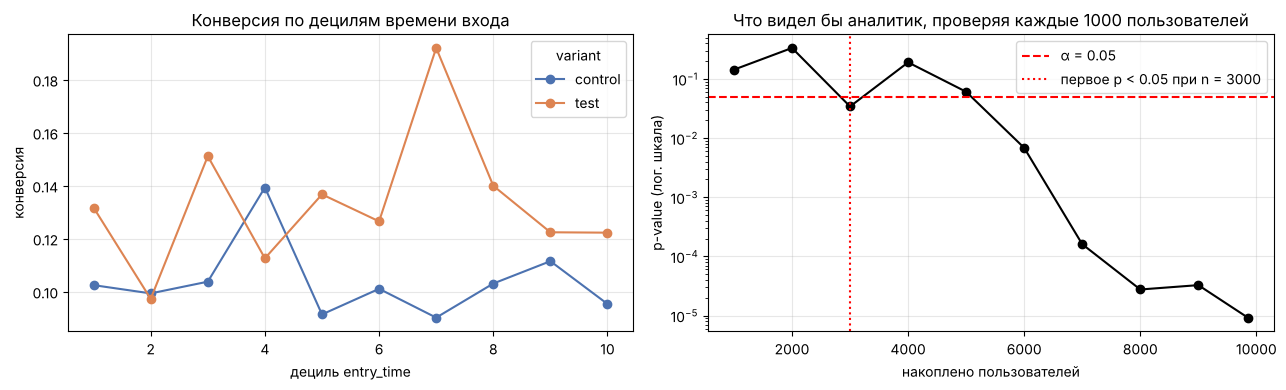

   n  p_value  lift_pp
1000   0.1433   2.9966
2000   0.3335   1.3562
3000   0.0342   2.4710
4000   0.1904   1.3511
5000   0.0606   1.7230
6000   0.0068   2.2662
7000   0.0002   2.9571
8000   0.0000   3.0769
9000   0.0000   2.8611
9853   0.0000   2.9130


In [14]:
# динамика конверсии по группам во времени: нет ли тренда, который мог бы «подсказать» момент остановки
conv_time = df.groupby(["time_decile", "variant"])["converted"].mean().unstack()

# путь p-value при подглядывании каждые 1000 пользователей (в порядке входа в эксперимент)
d_sorted = df.sort_values("entry_time").reset_index(drop=True)
checkpoints = list(range(1000, len(d_sorted) + 1, 1000))
if checkpoints[-1] != len(d_sorted):
    checkpoints.append(len(d_sorted))
peek = []
for k in checkpoints:
    s = d_sorted.iloc[:k]; a = s[s["is_test"] == 0]; b = s[s["is_test"] == 1]
    _, p = proportions_ztest([a["converted"].sum(), b["converted"].sum()], [len(a), len(b)])
    peek.append({"n": k, "p_value": p, "lift_pp": (b["converted"].mean() - a["converted"].mean()) * 100})
peek = pd.DataFrame(peek)
first_stop = peek.loc[peek["p_value"] < ALPHA, "n"].min()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
conv_time.plot(ax=axes[0], marker="o", color=[COLORS["control"], COLORS["test"]])
axes[0].set_title("Конверсия по децилям времени входа"); axes[0].set_xlabel("дециль entry_time"); axes[0].set_ylabel("конверсия")

axes[1].plot(peek["n"], peek["p_value"], "o-", color="k")
axes[1].axhline(ALPHA, ls="--", c="red", label="α = 0.05")
if pd.notna(first_stop):
    axes[1].axvline(first_stop, ls=":", c="red", label=f"первое p < 0.05 при n = {first_stop}")
axes[1].set_yscale("log"); axes[1].set_xlabel("накоплено пользователей"); axes[1].set_ylabel("p-value (лог. шкала)")
axes[1].set_title("Что видел бы аналитик, проверяя каждые 1000 пользователей"); axes[1].legend()
plt.tight_layout(); plt.show()

print(peek.round(4).to_string(index=False))

**Вывод по peeking.** Прямых следов подглядывания в данных **нет**: распределения `entry_time` в группах совпадают (U-тест, KS, t-тест — все p существенно больше 0.05), доля test одинакова во всех децилях времени, корреляция времени с группой практически нулевая. Поэтому утверждать «в тесте систематически более поздние пользователи» я не могу — по данным это не так. (Замечание про генератор из раздела 0 подтвердилось: назначение по времени было перезаписано.)

Две оговорки, чтобы не сделать ложный вывод в другую сторону:
* Отсутствие временно́го дисбаланса **не доказывает**, что подглядывания не было. Если аналитик проверял p-value каждые 1000 пользователей, сами данные от этого не меняются — меняется только момент остановки. По данным видно, что «сырое» p-value (которое и смотрел бы аналитик) впервые опустилось ниже 0.05 примерно на 3000 пользователях, потом вернулось выше, а с ~6000 ушло ниже порога окончательно. Аналитик, останавливающий тест при первом p < 0.05, объявил бы победу уже на 3000 — на выборке втрое меньше итоговой. Это ровно тот механизм, из-за которого при подглядывании реальная вероятность ложной находки намного выше заявленных 5 %.
* Единичный тест на уровне 0.05 сам по себе ошибается в 5 % случаев: при другом seed дисбаланс по времени мог бы «найтись» случайно — ещё один довод смотреть не только на p-value, но и на размер различий (здесь SMD по `entry_time` около нуля).

Честный итог: по данным peeking не подтверждён, но и исключить его нельзя; защита от него — заранее зафиксированный размер выборки или последовательные методы (например, альфа-спендинг), а не разовая проверка post factum.

## 5. Коррекция: что можно спасти, а что нет

Найденные нарушения делятся на две группы.

**Поддаётся аналитической коррекции** — дисбаланс по наблюдаемой ковариате `weekend`. Для него применю четыре метода и сравню с «сырой» оценкой из п. 3:
1. **IPW (взвешивание по обратной вероятности)**: вероятность попасть в test зависит только от `weekend`, поэтому propensity score — это просто доля test внутри каждого значения `weekend`; вес пользователя = 1 / P(его группа | weekend).
2. **Стратификация**: эффект считается отдельно в будни и в выходные, затем усредняется с весами, равными долям страт.
3. **Регрессионная корректировка**: линейная модель `converted ~ is_test + weekend` (коэффициент — разница в п.п. при одинаковом `weekend`; робастные ошибки), для контроля знака — логистическая.
4. **CUPED** с `weekend` как доэкспериментальной ковариатой: `Y_adj = Y − θ·(X − mean X)`, где θ — наклон регрессии Y на X. Важно: CUPED придуман для *снижения дисперсии* при честной рандомизации; при дисбалансе ковариаты он работает как регрессионная корректировка, и это нужно проговаривать.

**Не поддаётся коррекции** — SRM (неизвестно, кто и почему потерян), guardrail (фича технически хуже), возможный peeking (неизвестен протокол остановки), артефакт в platform 2 (поправка на `weekend` его не убирает — и не должна, потому что это не confounder, а отдельный подозрительный сигнал). Об этом — в конце раздела.

In [15]:
# ---- 5.1 IPW по weekend
ps_by_wk = df.groupby("weekend")["is_test"].mean()          # P(test | weekend)
df["ps"] = df["weekend"].map(ps_by_wk)
df["w"] = np.where(df["is_test"] == 1, 1 / df["ps"], 1 / (1 - df["ps"]))
print("Propensity score P(test | weekend):"); print(ps_by_wk.round(3))
print(f"Веса: от {df['w'].min():.2f} до {df['w'].max():.2f}")

def w_mean(x, w):
    return np.average(x, weights=w)

def ipw_diff(d):
    cc, tt = d["is_test"] == 0, d["is_test"] == 1
    return w_mean(d.loc[tt, "converted"], d.loc[tt, "w"]) - w_mean(d.loc[cc, "converted"], d.loc[cc, "w"])

# баланс после взвешивания
wk_bal_c = w_mean(df.loc[c_mask, "weekend"], df.loc[c_mask, "w"]); wk_bal_t = w_mean(df.loc[t_mask, "weekend"], df.loc[t_mask, "w"])
print(f"Доля weekend после взвешивания: control = {wk_bal_c:.3f}, test = {wk_bal_t:.3f} (до: {wk_c.mean():.3f} / {wk_t.mean():.3f})")

ipw_point = ipw_diff(df)
rng = np.random.default_rng(MY_SEED + 1)
boot = [ipw_diff(df.iloc[rng.integers(0, len(df), len(df))]) for _ in range(2000)]
ipw_ci = np.percentile(boot, [2.5, 97.5])
print(f"\nIPW-оценка эффекта: {ipw_point * 100:+.2f} п.п., 95% бутстрап-ДИ [{ipw_ci[0] * 100:+.2f}; {ipw_ci[1] * 100:+.2f}]")

Propensity score P(test | weekend):
weekend
0    0.250
1    0.757
Name: is_test, dtype: float64
Веса: от 1.32 до 4.12
Доля weekend после взвешивания: control = 0.299, test = 0.299 (до: 0.121 / 0.564)



IPW-оценка эффекта: +0.55 п.п., 95% бутстрап-ДИ [-0.92; +1.96]


In [16]:
# ---- 5.2 Стратификация по weekend
strata = []
for wk, g in df.groupby("weekend"):
    gc, gt = g[g["is_test"] == 0], g[g["is_test"] == 1]
    d = gt["converted"].mean() - gc["converted"].mean()
    se = np.sqrt(gc["converted"].var(ddof=1) / len(gc) + gt["converted"].var(ddof=1) / len(gt))
    strata.append({"weekend": wk, "n": len(g), "weight": len(g) / len(df), "conv_control": gc["converted"].mean(),
                   "conv_test": gt["converted"].mean(), "diff_pp": d * 100, "se_pp": se * 100})
strata = pd.DataFrame(strata).set_index("weekend")
strat_point = (strata["weight"] * strata["diff_pp"]).sum()
strat_se = np.sqrt((strata["weight"] ** 2 * strata["se_pp"] ** 2).sum())
strat_ci = strat_point + np.array([-1, 1]) * 1.96 * strat_se
p_strat = 2 * stats.norm.sf(abs(strat_point / strat_se))
print(strata.round(4))
print(f"\nСтратифицированная оценка: {strat_point:+.2f} п.п., 95% ДИ [{strat_ci[0]:+.2f}; {strat_ci[1]:+.2f}], p = {p_strat:.3f}")

            n  weight  conv_control  conv_test  diff_pp   se_pp
weekend                                                        
0        6909  0.7012        0.0963     0.1060   0.9669  0.8467
1        2944  0.2988        0.1583     0.1538  -0.4452  1.5660

Стратифицированная оценка: +0.55 п.п., 95% ДИ [-0.94; +2.03], p = 0.471


In [17]:
# ---- 5.3 Регрессионная корректировка
ols_wk = smf.ols("converted ~ is_test + weekend", data=df).fit(cov_type="HC1")
ols_wk_pl = smf.ols("converted ~ is_test + weekend + C(platform)", data=df).fit(cov_type="HC1")
logit_wk = smf.logit("converted ~ is_test + weekend", data=df).fit(disp=0)
ci_ols = ols_wk.conf_int().loc["is_test"] * 100

print(f"OLS (HC1) converted ~ is_test + weekend:")
print(f"  эффект test = {ols_wk.params['is_test'] * 100:+.2f} п.п., 95% ДИ [{ci_ols[0]:+.2f}; {ci_ols[1]:+.2f}], p = {ols_wk.pvalues['is_test']:.3f}")
print(f"  вклад weekend = {ols_wk.params['weekend'] * 100:+.2f} п.п. (p = {ols_wk.pvalues['weekend']:.1e}) — ковариата действительно влияет на конверсию")
print(f"OLS + platform: эффект test = {ols_wk_pl.params['is_test'] * 100:+.2f} п.п., p = {ols_wk_pl.pvalues['is_test']:.3f}")
print(f"Logit: коэффициент test = {logit_wk.params['is_test']:+.3f}, p = {logit_wk.pvalues['is_test']:.3f} (знак и значимость совпадают с OLS)")

OLS (HC1) converted ~ is_test + weekend:
  эффект test = +0.55 п.п., 95% ДИ [-0.93; +2.03], p = 0.465
  вклад weekend = +5.34 п.п. (p = 4.3e-10) — ковариата действительно влияет на конверсию
OLS + platform: эффект test = +0.55 п.п., p = 0.470
Logit: коэффициент test = +0.054, p = 0.458 (знак и значимость совпадают с OLS)


In [18]:
# ---- 5.4 CUPED с weekend как доэкспериментальной ковариатой
X, Y = df["weekend"].astype(float), df["converted"].astype(float)
theta = np.cov(Y, X, ddof=1)[0, 1] / X.var(ddof=1)        # наклон регрессии Y на X по всей выборке
df["converted_cuped"] = Y - theta * (X - X.mean())

cu_c, cu_t = df.loc[c_mask, "converted_cuped"], df.loc[t_mask, "converted_cuped"]
cuped_point = cu_t.mean() - cu_c.mean()
cuped_se = np.sqrt(cu_c.var(ddof=1) / n_c + cu_t.var(ddof=1) / n_t)
cuped_ci = cuped_point + np.array([-1, 1]) * 1.96 * cuped_se
p_cuped = stats.ttest_ind(cu_c, cu_t, equal_var=False).pvalue
var_reduction = 1 - df["converted_cuped"].var() / Y.var()

print(f"θ = {theta:.4f} (≈ прирост конверсии в выходные)")
print(f"CUPED-оценка эффекта: {cuped_point * 100:+.2f} п.п., 95% ДИ [{cuped_ci[0] * 100:+.2f}; {cuped_ci[1] * 100:+.2f}], p = {p_cuped:.3f}")
print(f"Снижение дисперсии метрики за счёт CUPED: {var_reduction * 100:.1f} % (ковариата бинарная и слабая — выигрыш небольшой)")

θ = 0.0562 (≈ прирост конверсии в выходные)
CUPED-оценка эффекта: +0.43 п.п., 95% ДИ [-0.88; +1.74], p = 0.523
Снижение дисперсии метрики за счёт CUPED: 0.6 % (ковариата бинарная и слабая — выигрыш небольшой)


,метод,"эффект, п.п.","ДИ 95%, п.п.",p-value,значимо (α=0.05)
0,Сырая разница (п. 3),2.9130,[+1.60; +4.23],0.0000,True
1,IPW по weekend,0.5450,[-0.92; +1.96],NaN,False
2,Стратификация по weekend,0.5450,[-0.94; +2.03],0.4709,False
3,Регрессия (OLS + weekend),0.5510,[-0.93; +2.03],0.4653,False
4,CUPED (weekend),0.4273,[-0.88; +1.74],0.5228,False


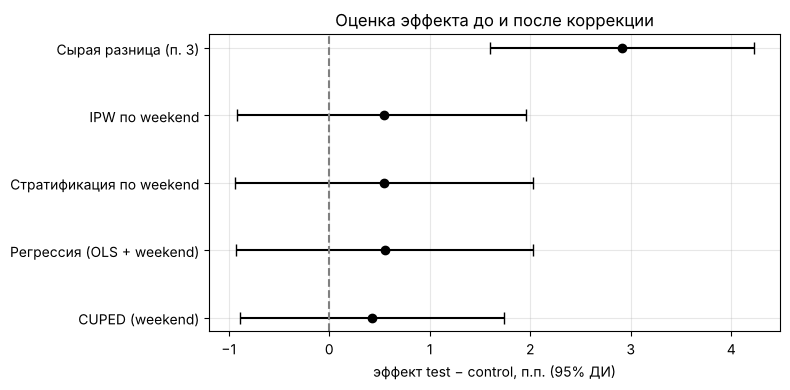

In [19]:
# ---- сводка: сырая оценка vs четыре метода коррекции
results = pd.DataFrame({
    "метод": ["Сырая разница (п. 3)", "IPW по weekend", "Стратификация по weekend", "Регрессия (OLS + weekend)", "CUPED (weekend)"],
    "эффект, п.п.": [lift_abs * 100, ipw_point * 100, strat_point, ols_wk.params["is_test"] * 100, cuped_point * 100],
    "ДИ 95%, п.п.": [f"[{ci_lift[0]*100:+.2f}; {ci_lift[1]*100:+.2f}]", f"[{ipw_ci[0]*100:+.2f}; {ipw_ci[1]*100:+.2f}]",
                     f"[{strat_ci[0]:+.2f}; {strat_ci[1]:+.2f}]", f"[{ci_ols[0]:+.2f}; {ci_ols[1]:+.2f}]",
                     f"[{cuped_ci[0]*100:+.2f}; {cuped_ci[1]*100:+.2f}]"],
    "p-value": [p_conv, np.nan, p_strat, ols_wk.pvalues["is_test"], p_cuped],
})
results["значимо (α=0.05)"] = results["p-value"] < ALPHA
display(results.round(4))

fig, ax = plt.subplots(figsize=(8, 4))
lo = [ci_lift[0] * 100, ipw_ci[0] * 100, strat_ci[0], ci_ols[0], cuped_ci[0] * 100]
hi = [ci_lift[1] * 100, ipw_ci[1] * 100, strat_ci[1], ci_ols[1], cuped_ci[1] * 100]
est = results["эффект, п.п."].values
ax.errorbar(est, range(len(est)), xerr=[est - np.array(lo), np.array(hi) - est], fmt="o", capsize=4, color="k")
ax.axvline(0, ls="--", c="gray"); ax.set_yticks(range(len(est))); ax.set_yticklabels(results["метод"])
ax.invert_yaxis(); ax.set_xlabel("эффект test − control, п.п. (95% ДИ)"); ax.set_title("Оценка эффекта до и после коррекции")
plt.tight_layout(); plt.show()

**Что дала коррекция.** Четыре метода согласны между собой: после учёта `weekend` эффект падает с ≈ +3 п.п. до ≈ +0.5 п.п., доверительные интервалы накрывают ноль, p-value ≈ 0.4–0.5. То есть почти весь «эффект фичи» из п. 3 — это эффект выходного дня, который достался test из-за кривой рандомизации. CUPED здесь дал практически то же, что регрессия (ожидаемо: с одной бинарной ковариатой это по сути та же модель; небольшое расхождение — из-за того, что θ оценивается по объединённой выборке с дисбалансом), а снижение дисперсии — небольшое: ковариата слабая.

Остаток около +0.5 п.п. — не шум, а след **артефакта в platform 2**. Проверяю: эффект с поправкой на `weekend` без этого сегмента и модель с взаимодействием «группа × платформа».

In [20]:
# ---- вклад platform 2 в остаточный эффект
ols_no2 = smf.ols("converted ~ is_test + weekend", data=df[df["platform"] != 2]).fit(cov_type="HC1")
ols_int = smf.ols("converted ~ is_test * C(platform) + weekend", data=df).fit(cov_type="HC1")
share_p2 = (df["platform"] == 2).mean()

print(f"Эффект с поправкой на weekend БЕЗ platform 2: {ols_no2.params['is_test'] * 100:+.2f} п.п., p = {ols_no2.pvalues['is_test']:.3f}")
print(f"Модель с взаимодействием (базовая платформа 0):")
print(f"  эффект test на platform 0: {ols_int.params['is_test'] * 100:+.2f} п.п., p = {ols_int.pvalues['is_test']:.3f}")
print(f"  добавка на platform 1:     {ols_int.params['is_test:C(platform)[T.1]'] * 100:+.2f} п.п., p = {ols_int.pvalues['is_test:C(platform)[T.1]']:.3f}")
print(f"  добавка на platform 2:     {ols_int.params['is_test:C(platform)[T.2]'] * 100:+.2f} п.п., p = {ols_int.pvalues['is_test:C(platform)[T.2]']:.3f}")
print(f"\nДоля platform 2 в выборке: {share_p2:.1%}; её вклад в общий скорректированный эффект ≈ "
      f"{share_p2 * seg.loc[2, 'lift_adj_pp']:+.2f} п.п. — это и есть почти весь остаток")

Эффект с поправкой на weekend БЕЗ platform 2: -0.14 п.п., p = 0.859
Модель с взаимодействием (базовая платформа 0):
  эффект test на platform 0: -0.26 п.п., p = 0.788
  добавка на platform 1:     +0.21 п.п., p = 0.883
  добавка на platform 2:     +7.01 п.п., p = 0.003

Доля platform 2 в выборке: 10.4%; её вклад в общий скорректированный эффект ≈ +0.66 п.п. — это и есть почти весь остаток


**Итог по коррекции.** Вне platform 2 эффект фичи после поправки на `weekend` равен нулю (с точностью до шума). Весь остаточный «плюс» сосредоточен в одном небольшом сегменте, где test выигрывает ≈ +6–7 п.п. и это переживает все поправки. По данным нельзя отличить, что это: реальный эффект на одной платформе, баг трекинга на этой платформе или ещё один артефакт. Единственный корректный путь — отдельный заранее спланированный тест на platform 2.

**Чего коррекция не исправляет и почему:**
* **SRM** — взвешивание уравнивает *наблюдаемые* характеристики, но если из одной группы потерялись пользователи по неизвестной причине, никакие веса не вернут их в выборку. Группы после IPW «равны по weekend», но не по тому, чего мы не видим.
* **Guardrail** — это не статистическая проблема, а продуктовая: фича в 3,5 раза чаще ломает страницу. Исправляется кодом, а не анализом.
* **Peeking** — по данным не подтверждён, но протокол остановки неизвестен; защита — фиксированный размер выборки или последовательный дизайн при перезапуске.
* **Общее**: все четыре метода опираются на допущение «нет ненаблюдаемых confounder'ов». В тесте с нарушенной рандомизацией это допущение ничем не гарантировано — коррекция даёт лучшую из доступных оценок, но не заменяет честный эксперимент.

## 6. Финальное решение

In [21]:
print("Найденные нарушения:")
for i, w in enumerate(warnings_list, 1):
    print(f"  {i}. {w}")

print(f"\nЭффект фичи на конверсию: сырой {lift_abs * 100:+.2f} п.п. (p = {p_conv:.1e}) → "
      f"после поправки на weekend {ols_wk.params['is_test'] * 100:+.2f} п.п. (p = {ols_wk.pvalues['is_test']:.2f}) → "
      f"без сегмента platform 2 {ols_no2.params['is_test'] * 100:+.2f} п.п. (p = {ols_no2.pvalues['is_test']:.2f})")
print(f"Guardrail: ошибки {r_t:.1%} в test против {r_c:.1%} в control (риск ×{rr:.1f}, p = {p_err:.1e})")

# сколько пользователей нужно при перезапуске, чтобы уверенно поймать +1 п.п. к базовой конверсии
mde = 0.01
eff = proportion_effectsize(p_c + mde, p_c)
n_per_group = NormalIndPower().solve_power(effect_size=eff, alpha=0.05, power=0.8, ratio=1)
print(f"\nДля перезапуска: чтобы обнаружить +{mde * 100:.0f} п.п. к базе {p_c:.1%} (мощность 80 %, α = 0.05), "
      f"нужно ≈ {n_per_group:,.0f} пользователей в каждой группе (сейчас {n_c} и {n_t})")

print("\n>>> РЕШЕНИЕ: НЕ ROLLOUT. Повторить эксперимент с изменениями (см. ниже).")

Найденные нарушения:
  1. SRM: доля test 0.402 вместо 0.5 (p = 5.6e-85)
  2. Confounder: доля weekend в test 0.56 против 0.12 в control (p < 1e-300)
  3. Guardrail: ошибки 0.061 в test против 0.018 в control, риск ×3.5 (p = 7.0e-31)
  4. Изолированный сигнал в сегменте platform=[2] (post-hoc, малый сегмент)

Эффект фичи на конверсию: сырой +2.91 п.п. (p = 9.2e-06) → после поправки на weekend +0.55 п.п. (p = 0.47) → без сегмента platform 2 -0.14 п.п. (p = 0.86)
Guardrail: ошибки 6.1% в test против 1.8% в control (риск ×3.5, p = 7.0e-31)

Для перезапуска: чтобы обнаружить +1 п.п. к базе 10.4% (мощность 80 %, α = 0.05), нужно ≈ 15,213 пользователей в каждой группе (сейчас 5896 и 3957)

>>> РЕШЕНИЕ: НЕ ROLLOUT. Повторить эксперимент с изменениями (см. ниже).


**Решение: не запускать фичу; повторить тест с изменениями.**

Обоснование цифрами:
1. **Guardrail нарушен** — ошибок в test ≈ 6 % против ≈ 2 % в control (риск в 3,5 раза выше, p ≈ 10⁻³¹). Уже этого достаточно для остановки.
2. **Рандомизация сломана** — SRM (доля test ≈ 0.40, p ≈ 10⁻⁸⁵) и confounder по `weekend` (56 % против 12 %). Результатам такого теста доверять нельзя в принципе.
3. **Эффекта на конверсию нет** — после поправки на `weekend` +3 п.п. превращаются в ≈ +0.5 п.п. (p ≈ 0.5), а без сегмента platform 2 — в ноль. «Победа» из п. 3 была артефактом распределения выходных пользователей.
4. **Сигнал в platform 2** (+6–7 п.п. после всех поправок) — post-hoc находка в сегменте ~10 % выборки; это гипотеза для отдельного теста, а не основание для запуска.
5. **Peeking** по данным не подтверждён, но и не исключён — протокол остановки нужно зафиксировать заранее.

Что изменить при повторе:
* **Сплит**: назначать группу по хэшу `user_id` с именем эксперимента (чтобы назначение не зависело ни от дня недели, ни от платформы, ни от времени входа); прогнать A/A-тест; ежедневно мониторить SRM со строгим порогом и баланс ключевых ковариат (`weekend`, `platform`).
* **Качество фичи**: найти и исправить причину ошибок загрузки в test; при повторе — автоматическая остановка при превышении guardrail.
* **Протокол анализа**: заранее зафиксировать размер выборки (≈ 15 тыс. на группу для MDE +1 п.п. при базе ~10 %) или использовать последовательный дизайн; запретить промежуточные остановки «по p-value».
* **Сегменты**: заявить гипотезу про platform 2 до запуска и проверить её как отдельную (с собственной мощностью), а общий эффект оценивать по всем платформам с заранее оговорённой поправкой на множественные проверки.
* **Ковариаты**: собирать `weekend` и активность до теста, чтобы при анализе применять CUPED/регрессию для снижения дисперсии — но уже на честно рандомизированных данных.

## 7. Общий вывод

Аудит теста по файлу `exp_data_seed_960134.csv` показал, что эксперимент **невалиден**, а положительный результат по конверсии — артефакт:

| Проблема | Как обнаружена | Что с ней делать |
|---|---|---|
| **SRM**: доля test ≈ 0.40 вместо 0.50 | хи-квадрат / биномиальный тест, p ≈ 10⁻⁸⁵ | починить сплит, A/A-тест, ежедневный мониторинг; коррекцией не лечится |
| **Confounder `weekend`**: 56 % в test против 12 % в control | z-тест / хи-квадрат, SMD ≈ 1; P(test \| weekend) 0.76 vs 0.25 | IPW / стратификация / регрессия / CUPED: эффект +3 п.п. → ≈ +0.5 п.п. (не значимо) |
| **Guardrail**: ошибки ≈ 6 % против ≈ 2 % | z-тест, Фишер, относительный риск ×3,5 с ДИ | остановить тест, чинить фичу |
| **Сегменты**: «значимость» в platform 0 и 2 после Бонферрони; после поправки на `weekend` — только platform 2 (+6–7 п.п.) | z-тесты по сегментам, Бонферрони и FDR, регрессия внутри сегментов, модель с взаимодействием | post-hoc гипотеза → отдельный запланированный тест |
| **Peeking**: дисбаланса по `entry_time` нет | U-тест, KS, доля test по децилям времени, путь p-value при проверках каждые 1000 пользователей | не подтверждён, но при подглядывании аналитик остановился бы уже на ~3000 пользователях → фиксировать размер выборки / последовательный дизайн |

**Продуктовое решение: не rollout; повторить с изменениями** (сплит по хэшу, исправление ошибок, фиксированный размер выборки, предзаявленная гипотеза по platform 2).

Главный урок: порядок проверок важен. Сначала SRM и баланс ковариат, затем guardrail, и только потом — первичная метрика. Аналитик, который пропустил первые два шага, увидел бы «+28 % конверсии, p < 0.001» и запустил фичу, которая не работает и ломает страницу у 6 % пользователей вместо 2 %.